# plot_HS_regions_map — regional uncertainty "dashboard" matched to continents

A map-based composite of the CESM2 MA-GAUSS regional analysis: the 8 IPCC-WGII
continental regions are drawn on a world map (coloured with `Spectral(8)`, the
same scheme as the MATLAB `HS_plot_map`), and each region is annotated with a
two-panel inset — **top: the change time series** (per-strategy ensemble means,
thin members, and the black SSP2-4.5 baseline) and **bottom: the variance
partition** (Scenario / Strategy / Internal) — connected to its continent by a
leader line. The global panels sit at the top-left.

This combines the line panels of `plot_regions_T`/`plot_regions_P` with the
partition panels, laid out around the map. Two dashboards are produced, for
surface temperature (`TREFHT`, K) and precipitation (`PRECT`, % vs the
2020-2039 reference, as in `plot_regions_P`).

Self-contained: reads the raw CESM data from `/Volumes/D_Visioni2/CESM2_MA/`.

In [1]:
import sys, os, glob
import os as _os
_r = _os.getcwd()
while not _os.path.isdir(_os.path.join(_r, "python")) and _os.path.dirname(_r) != _r:
    _r = _os.path.dirname(_r)
_os.chdir(_r)   # notebooks live in j_notebooks/; anchor to project root
sys.path.insert(0, "python")
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from matplotlib.patches import ConnectionPatch
import mat_utils as mu
from mat_utils import brewermap, movmean, shaperead, inpolygon

fold = "/Volumes/D_Visioni2/CESM2_MA/MA_GAUSS/"
fold2 = "/Volumes/D_Visioni2/CESM2_MA/"
nam = "b.e21.BWSSP245.f09_g17.release-cesm2.1.3.WACCM-MA-1deg."
exp = ["feedback_30N_30S", "feedback_15N_15S", "feedback_0N_1.0", "feedback_60N_60S_1.0",
       "SSP245-MA-GAUSS-DEFAULT", "SSP245-MA-GAUSS-LOWER-0.5", "SSP245-MA-GAUSS-LOWER-1.0"]
exp2 = ["1.0 above PI - 30-30", "1.0 above PI - 15-15", "1.0 above PI - EQ",
        "1.0 above PI - 60-60", "1.5 above PI - MS", "1.0 above PI - MS", "0.5 above PI - MS"]
ids = ".cam.h0."
ens = ["001", "002", "003"]
nums = [3, 3, 3, 3, 3, 3, 3]
fc = brewermap(7, "Set2")
AREA_C = [(0, 0.4470, 0.7410), (0.8500, 0.3250, 0.0980), (0.9290, 0.6940, 0.1250)]
time = np.arange(2035, 2070)
timeb = np.arange(2015, 2100)
ref = slice(5, 25)

## Data loading (TREFHT and PRECT ensembles + SSP2-4.5 baseline)

In [2]:
def load_var(var):
    """Return ta (lon,lat,420,7,3), b1 baseline (lon,lat,1020,3), lat, lon."""
    ta = None
    pat = "PRECT" if var == "PRECT" else var
    for ix, ex in enumerate(exp):
        for ie, en in enumerate(ens):
            f = sorted(glob.glob(f"{fold}{nam}{ex}.{en}{ids}{pat}*.nc"))[0]
            t = mu.ncread(f, pat)[:, :, 0:420].astype(np.float32)
            if ta is None:
                ta = np.empty(t.shape + (7, 3), dtype=np.float32)
            ta[:, :, :, ix, ie] = t
    lat = mu.ncread(f, "lat").ravel(); lon = mu.ncread(f, "lon").ravel()
    shp = ta.shape[:2]
    # MATLAB fills unassigned array elements with 0
    b1 = np.zeros(shp + (1020, 3), dtype=np.float32)
    if var == "TREFHT":
        b1[:, :, 0:600, 0] = mu.ncread(f"{fold2}{nam}{ens[0]}{ids}TREFHT.201501-206412.nc", "TREFHT")
        b1[:, :, 600:1020, 0] = mu.ncread(f"{fold2}{nam}{ens[0]}{ids}TREFHT.206501-209912.nc", "TREFHT")
        b1[:, :, 0:600, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}TREFHT.201501-206412.nc", "TREFHT")
        b1[:, :, 600:1008, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}TREFHT.206501-209812.nc", "TREFHT")
        b1[:, :, 0:60, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}TREFHT.201501-201912.nc", "TREFHT")
        b1[:, :, 60:660, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}TREFHT.202001-206912.nc", "TREFHT")
        b1[:, :, 660:1020, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}TREFHT.207001-209912.nc", "TREFHT")
    else:  # PRECT: member1 PRECT, members 2-3 PRECC+PRECL
        b1[:, :, 0:600, 0] = mu.ncread(f"{fold2}{nam}{ens[0]}{ids}PRECT.201501-206412.nc", "PRECT")
        b1[:, :, 600:1020, 0] = mu.ncread(f"{fold2}{nam}{ens[0]}{ids}PRECT.206501-209912.nc", "PRECT")
        b1[:, :, 0:600, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}PRECC.201501-206412.nc", "PRECC")
        b1[:, :, 600:1008, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}PRECC.206501-209812.nc", "PRECC")
        b1[:, :, 0:60, 2] = np.nan
        b1[:, :, 60:660, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}PRECC.202001-206912.nc", "PRECC")
        b1[:, :, 660:1020, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}PRECC.207001-209912.nc", "PRECC")
        b3 = np.zeros(shp + (1020, 3), dtype=np.float32)
        b3[:, :, 0:600, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}PRECL.201501-206412.nc", "PRECL")
        b3[:, :, 600:1008, 1] = mu.ncread(f"{fold2}{nam}{ens[1]}{ids}PRECL.206501-209812.nc", "PRECL")
        b3[:, :, 0:60, 2] = np.nan
        b3[:, :, 60:660, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}PRECL.202001-206912.nc", "PRECL")
        b3[:, :, 660:1020, 2] = mu.ncread(f"{fold2}{nam}{ens[2]}{ids}PRECL.207001-209912.nc", "PRECL")
        b1 = b1 + b3
    return ta, b1, lat, lon


def annual(x, n):
    return np.reshape(x, (12, n) + x.shape[1:], order="F").mean(axis=0)


def partition(y):
    iv = np.std(y[:, 4, :], axis=1, ddof=1) ** 2
    sv = np.std(y[:, [0, 1, 2, 3, 5], 0], axis=1, ddof=1) ** 2
    cv = np.std(y[:, 4:7, 0], axis=1, ddof=1) ** 2
    return iv, sv, cv


def compute(var, fact):
    """Global + per-WGII-region annual means and partitions."""
    ta, b1, lat, lon = load_var(var)
    ww = np.cos(lat / 180 * np.pi)
    regions = shaperead("IPCC_WGII_continental_regions.shx")
    latM, lonM = np.meshgrid(lat, lon - 180)

    # global (cosine-weighted)
    ta_zm = np.nanmean(ta, axis=0); tab_zm = np.nanmean(b1, axis=0)
    ta_gm = (ta_zm * ww[:, None, None, None]).sum(0) / ww.sum()
    tab_gm = (tab_zm * ww[:, None, None]).sum(0) / ww.sum()
    res = {"global": (annual(ta_gm, 35) * fact, annual(tab_gm, 85) * fact)}

    # per region (area-unweighted nanmean over masked pixels, as in plot_regions_*)
    res["regions"] = {}
    for r in regions:
        ind = inpolygon(latM, lonM, r.Y, r.X)
        ta_reg = np.nanmean(ta[ind], axis=0)         # (420,7,3)
        tab_reg = np.nanmean(b1[ind], axis=0)        # (1020,3)
        res["regions"][r.Region] = (annual(ta_reg, 35) * fact, annual(tab_reg, 85) * fact)
    del ta, b1
    return res, regions

## Panel drawing helpers

In [3]:
def line_panel(ax, y, yb, normalize, ylim):
    """Top sub-panel: change vs 2020-2039 reference (per-strategy means, thin
    members, black SSP2-4.5 baseline). normalize=True -> percent of baseline.
    ylim=None -> autoscale to this panel's own data min/max (with padding)."""
    lo, hi = [], []
    def rec(v):
        lo.append(np.nanmin(v)); hi.append(np.nanmax(v))
    for ix in range(7):
        tp = yb[ref, :].mean()
        for ie in range(nums[ix]):
            tpe = yb[ref, ie].mean()
            an = movmean(y[:, ix, ie] - yb[ref, ie].mean(), 10)
            v = an / tpe * 100 if normalize else an
            ax.plot(time, v, color=fc[ix], linewidth=.3); rec(v)
        an = np.mean(movmean(y[:, ix, :] - yb[ref, :].mean(0), 10), axis=1)
        v = an / tp * 100 if normalize else an
        ax.plot(time, v, color=fc[ix], linewidth=2.2); rec(v)
    tp = yb[ref, :].mean()
    for ie in range(3):
        an = movmean(yb[:, ie] - yb[ref, ie].mean(), 10)
        v = an / yb[ref, ie].mean() * 100 if normalize else an
        ax.plot(timeb, v, "k", linewidth=.3); rec(v)
    anb = np.mean(movmean(yb - yb[ref, :].mean(0), 10), axis=1)
    v = anb / tp * 100 if normalize else anb
    ax.plot(timeb, v, "k", linewidth=2.2); rec(v)
    ax.axhline(0, color="k", linewidth=.6)
    ax.set_xlim(2035, 2069)
    if ylim is None:                       # autoscale to data (per-continent)
        a, b = float(np.nanmin(lo)), float(np.nanmax(hi)); p = 0.08 * max(b - a, 1e-9)
        ax.set_ylim(a - p, b + p)
    else:
        ax.set_ylim(*ylim)
    ax.tick_params(labelsize=6); ax.set_xticklabels([])


def part_panel(ax, y):
    """Bottom panel: variance partition (Scenario/Strategy/Internal)."""
    iv, sv, cv = partition(y); tot = iv + sv + cv
    ax.fill_between(time, movmean((sv + iv + cv) / tot * 100, 10), 0, color=AREA_C[0])
    ax.fill_between(time, movmean((sv + iv) / tot * 100, 10), 0, color=AREA_C[1])
    ax.fill_between(time, movmean(iv / tot * 100, 10), 0, color=AREA_C[2])
    ax.set_xlim(2035, 2069); ax.set_ylim(0, 100)
    ax.set_xticks([2040, 2060]); ax.tick_params(labelsize=6)

## Dashboard layout
Region blocks (line panel above partition panel, identical size) sit on a tidy
grid: a row of four along the top, a row of four along the bottom, the global
block at middle-left, the map centred, and a combined legend at middle-right.
Leader lines link each block to its continent.

In [4]:
import matplotlib.patches as mpatches

COLS = [0.035, 0.275, 0.515, 0.755]      # left edge of the 4 aligned columns
BW = 0.205                                # block width
HL, HP, GAP = 0.115, 0.130, 0.012         # line height, partition height, intra-block gap
TOP_PB, BOT_PB = 0.680, 0.050             # partition-axis bottom: top row / bottom row
# region -> (column-left x, "top"/"bot" row, map-anchor lon, lat)
SLOTS = {
    "North America":             (COLS[0], "top", -100,  45),
    "Small Islands":             (COLS[1], "top",  -60,  14),
    "Europe":                    (COLS[2], "top",   18,  52),
    "Asia":                      (COLS[3], "top",   95,  45),
    "Central and South America": (COLS[0], "bot",  -62, -15),
    "Antarctica":                (COLS[1], "bot",    0, -82),
    "Africa":                    (COLS[2], "bot",   22,   3),
    "Australasia":               (COLS[3], "bot",  140, -25),
}


def dashboard(res, regions, var_label, normalize, default_ylim, glob_ylim, outname):
    fig = plt.figure(figsize=(22, 13))
    fc_map = brewermap(8, "Spectral")

    # central map
    axm = fig.add_axes([0.305, 0.355, 0.40, 0.31], projection=ccrs.PlateCarree())
    axm.set_global()
    for i, r in enumerate(regions):
        x = np.asarray(r.X, float); yy = np.asarray(r.Y, float); s = 0
        for k in range(len(x) + 1):
            if k == len(x) or np.isnan(x[k]):
                if k > s:
                    axm.fill(x[s:k], yy[s:k], transform=ccrs.PlateCarree(),
                             facecolor=fc_map[i], edgecolor="none", zorder=1)
                s = k + 1
    axm.coastlines(linewidth=0.4, color="k"); axm.set_frame_on(False)

    # global block (middle-left)
    yg, ybg = res["global"]
    axgl = fig.add_axes([0.035, 0.520, BW, HL]); axgp = fig.add_axes([0.035, 0.375, BW, HP])
    line_panel(axgl, yg, ybg, normalize, glob_ylim)
    axgl.set_title("Global mean", fontsize=11, fontweight="bold")
    part_panel(axgp, yg)
    axgp.set_title("Global partition", fontsize=9)

    # combined legend (middle-right)
    axleg = fig.add_axes([0.775, 0.39, 0.21, 0.24]); axleg.axis("off")
    hs = [axleg.plot([], [], color=fc[ix], lw=3)[0] for ix in range(7)]
    hs.append(axleg.plot([], [], "k", lw=3)[0])
    leg1 = axleg.legend(hs, exp2 + ["SSP2-4.5"], loc="upper center", fontsize=8.5,
                        frameon=True, title="Time series (line panels)", title_fontsize=9)
    axleg.add_artist(leg1)
    parts = [mpatches.Patch(color=AREA_C[0], label="Scenario (target)"),
             mpatches.Patch(color=AREA_C[1], label="Strategy"),
             mpatches.Patch(color=AREA_C[2], label="Internal variability")]
    axleg.legend(handles=parts, loc="lower center", fontsize=8.5, frameon=True,
                 title="Uncertainty partition", title_fontsize=9)

    # region blocks + leader lines
    for r in regions:
        name = r.Region
        if name not in SLOTS:
            continue
        left, row, alon, alat = SLOTS[name]
        pb = TOP_PB if row == "top" else BOT_PB
        axP = fig.add_axes([left, pb, BW, HP])
        axL = fig.add_axes([left, pb + HP + GAP, BW, HL])
        y, yb = res["regions"][name]
        line_panel(axL, y, yb, normalize, default_ylim)
        axL.set_title(name, fontsize=11, fontweight="bold")
        part_panel(axP, y)
        # leader: top blocks leave from partition-bottom, bottom blocks from line-top
        anchor_ax = axP if row == "top" else axL
        con = ConnectionPatch(xyA=(alon, alat), coordsA=axm.transData,
                              xyB=(0.5, 0.0 if row == "top" else 1.0),
                              coordsB=anchor_ax.transAxes,
                              color="0.35", linewidth=1.2, zorder=0)
        fig.add_artist(con)

    fig.suptitle(f"CESM2 regional {var_label} strategy and target uncertainty (changes vs 2020-2039)",
                 fontsize=16, fontweight="bold", y=0.995)
    os.makedirs("py_outputs", exist_ok=True)
    fig.savefig(f"py_outputs/{outname}.png", dpi=300, bbox_inches="tight")
    plt.show()
    print("saved py_outputs/" + outname + ".png")

## Surface temperature dashboard (K)

/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


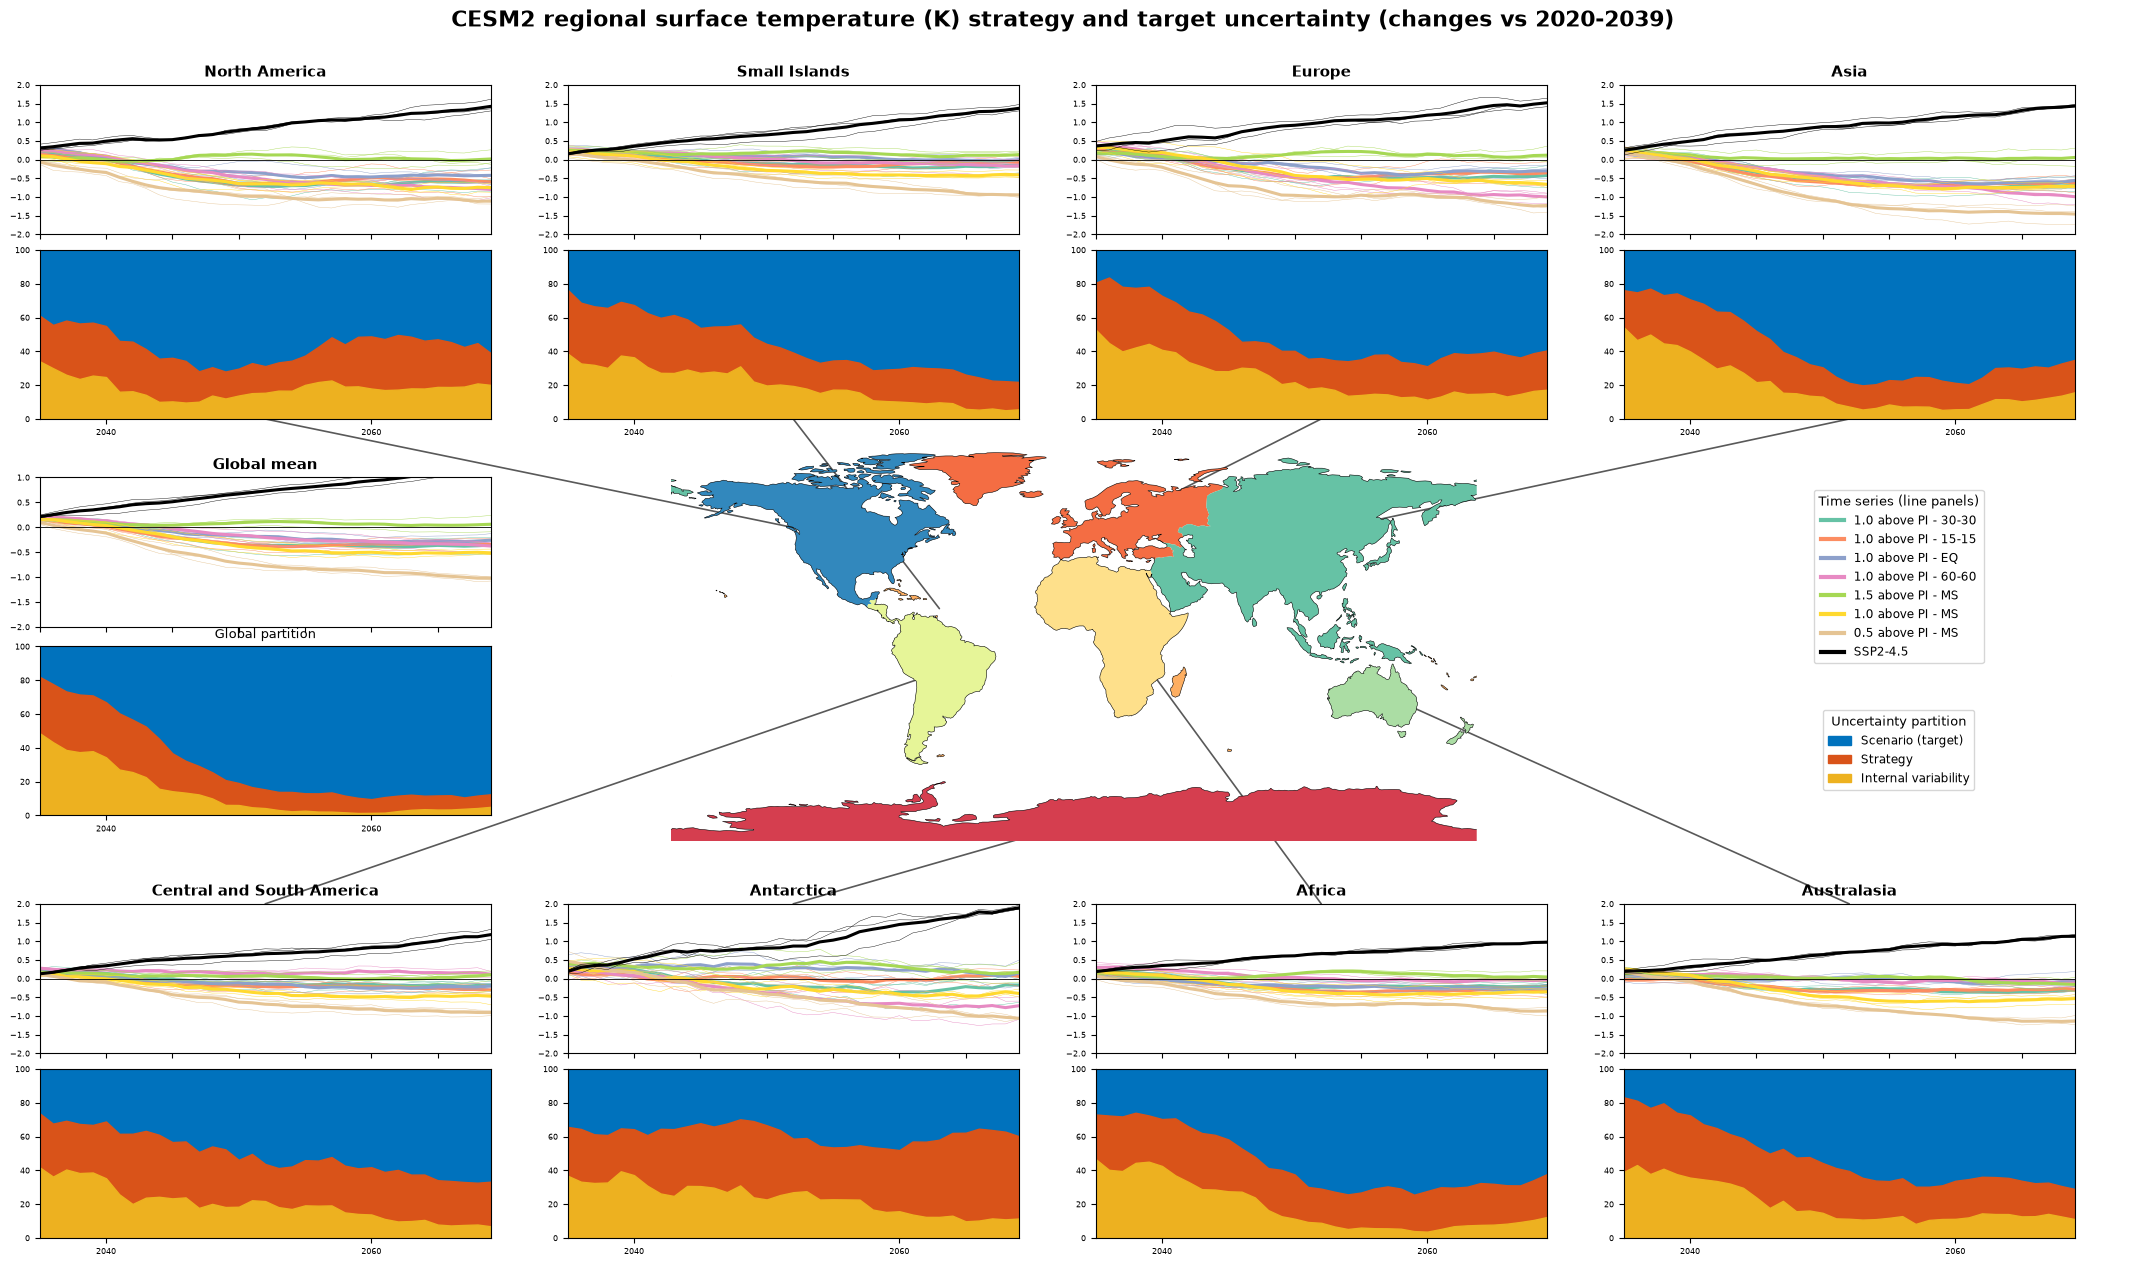

saved py_outputs/HS_plot_TREFHT_regions_map.png


In [5]:
res_t, regions = compute("TREFHT", 1.0)
dashboard(res_t, regions, "surface temperature (K)", normalize=False,
          default_ylim=(-2, 2), glob_ylim=(-2, 1), outname="HS_plot_TREFHT_regions_map")

## Precipitation dashboard (% vs 2020-2039)

/var/folders/t9/vl6_0lmn7w759j1nh0z6rblh0000gt/T/ipykernel_37287/994831468.py:61: RuntimeWarning: Mean of empty slice
  ta_zm = np.nanmean(ta, axis=0); tab_zm = np.nanmean(b1, axis=0)
/var/folders/t9/vl6_0lmn7w759j1nh0z6rblh0000gt/T/ipykernel_37287/994831468.py:71: RuntimeWarning: Mean of empty slice
  tab_reg = np.nanmean(b1[ind], axis=0)        # (1020,3)
/opt/anaconda3/envs/geomip/lib/python3.11/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


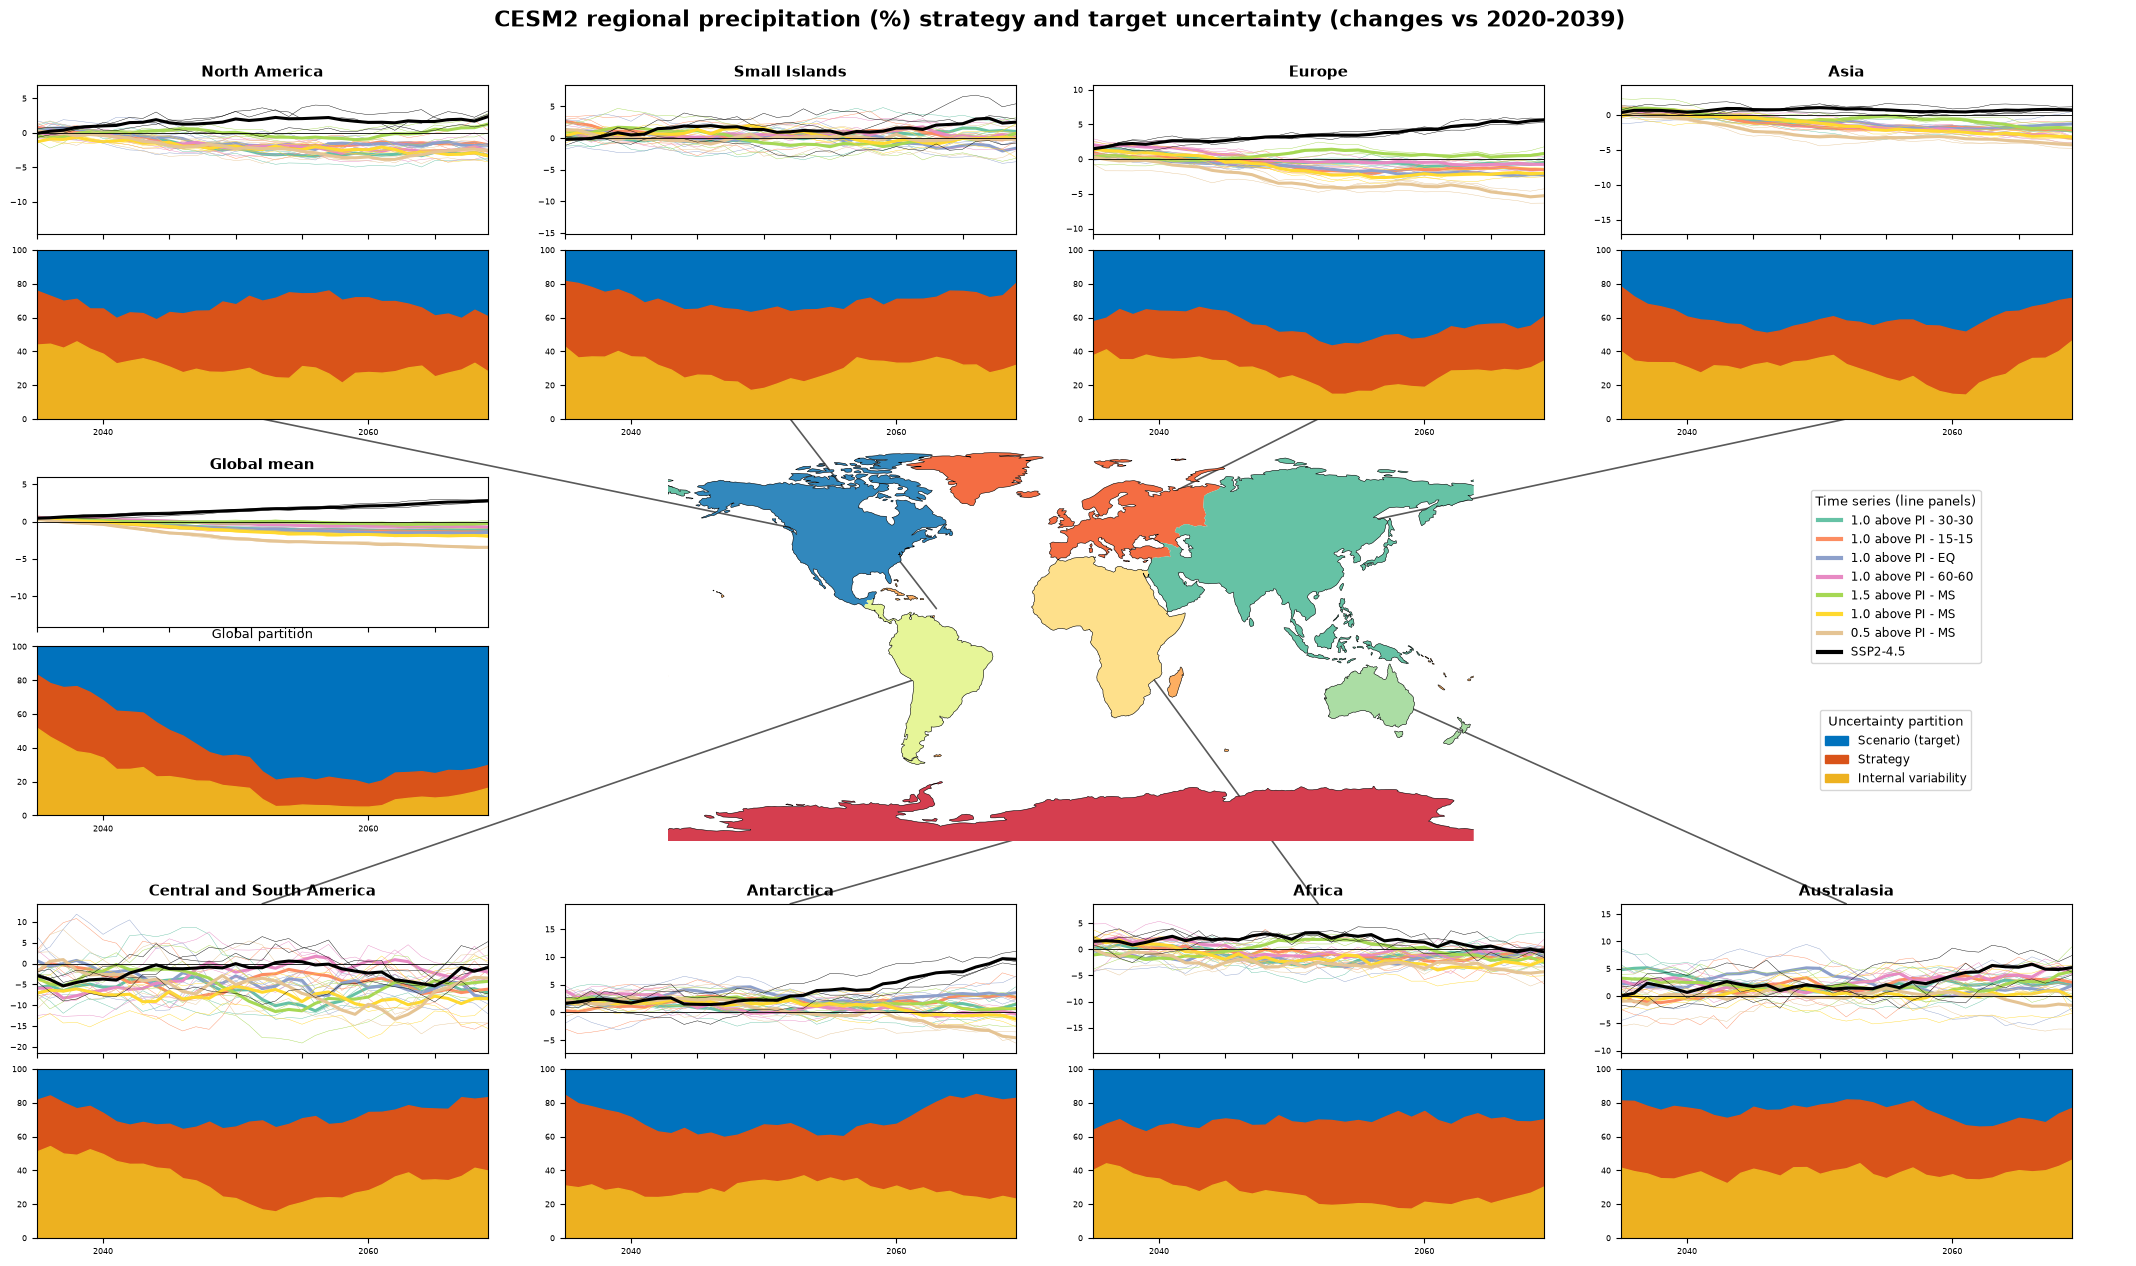

saved py_outputs/HS_plot_PRECT_regions_map.png


In [6]:
res_p, regions = compute("PRECT", 86400 * 1e3)
# default_ylim=None / glob_ylim=None -> each precip panel autoscales to its own
# continent's data range (no fixed +/-20% cap)
dashboard(res_p, regions, "precipitation (%)", normalize=True,
          default_ylim=None, glob_ylim=None, outname="HS_plot_PRECT_regions_map")